In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("")
df["body_text"] = df["body_text"].fillna("")
df["text"] = df["headline"] + " " + df["body_text"]

print(df["label"].value_counts())

label
Fake    1110
Real    1102
Name: count, dtype: int64


In [2]:
import nltk
from rake_nltk import Rake

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\hp\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
def extract_keywords(text):
    rake = Rake()
    rake.extract_keywords_from_text(str(text))
    
    keywords = rake.get_ranked_phrases_with_scores()
    
    return keywords[:10]

df["keywords"] = df["text"].apply(extract_keywords)

print(df[["label", "keywords"]].head())

  label                                           keywords
0  Real  [(16.0, global economy faces recession), (9.0,...
1  Real  [(25.0, panic spreads government sources state...
2  Fake  [(16.0, tech industry local administration), (...
3  Fake  [(9.0, prime minister attended), (9.0, dengue ...
4  Real  [(64.0, new virus outbreak sparks fear governm...


In [4]:
keyword_rows = []

for _, row in df.iterrows():
    for score, keyword in row["keywords"]:
        keyword_rows.append({
            "news_id": row["news_id"],
            "label": row["label"],
            "keyword": keyword,
            "rake_score": score
        })

keyword_df = pd.DataFrame(keyword_rows)

print(keyword_df.head())

   news_id label                                 keyword  rake_score
0        1  Real          global economy faces recession        16.0
1        1  Real                 prime minister attended         9.0
2        1  Real                   inauguration ceremony         4.0
3        1  Real                             chief guest         4.0
4        2  Real  panic spreads government sources state        25.0


In [5]:
keyword_comparison = (
    keyword_df.groupby(["label", "keyword"])
    .agg(
        frequency=("keyword", "count"),
        average_rake_score=("rake_score", "mean")
    )
    .reset_index()
)

fake_keywords = keyword_comparison[
    keyword_comparison["label"].str.lower() == "fake"
].sort_values("frequency", ascending=False)

real_keywords = keyword_comparison[
    keyword_comparison["label"].str.lower() == "real"
].sort_values("frequency", ascending=False)

print("Top keywords in Fake News:")
print(fake_keywords.head(20))

print("\nTop keywords in Real News:")
print(real_keywords.head(20))

Top keywords in Fake News:
    label                                keyword  frequency  \
4    Fake   bangladeshi astronaut captures photo        135   
0    Fake                           authenticity        129   
54   Fake                               incident        129   
6    Fake                           breakthrough        128   
2    Fake                             bangladesh        128   
104  Fake  significant technological advancement        123   
9    Fake                                   city        120   
56   Fake                          investigating        120   
116  Fake                          various parts        120   
67   Fake                                morning        120   
1    Fake                            authorities        120   
94   Fake                               reported        120   
51   Fake                      help avoid danger        117   
5    Fake                      basic precautions        117   
3    Fake                   

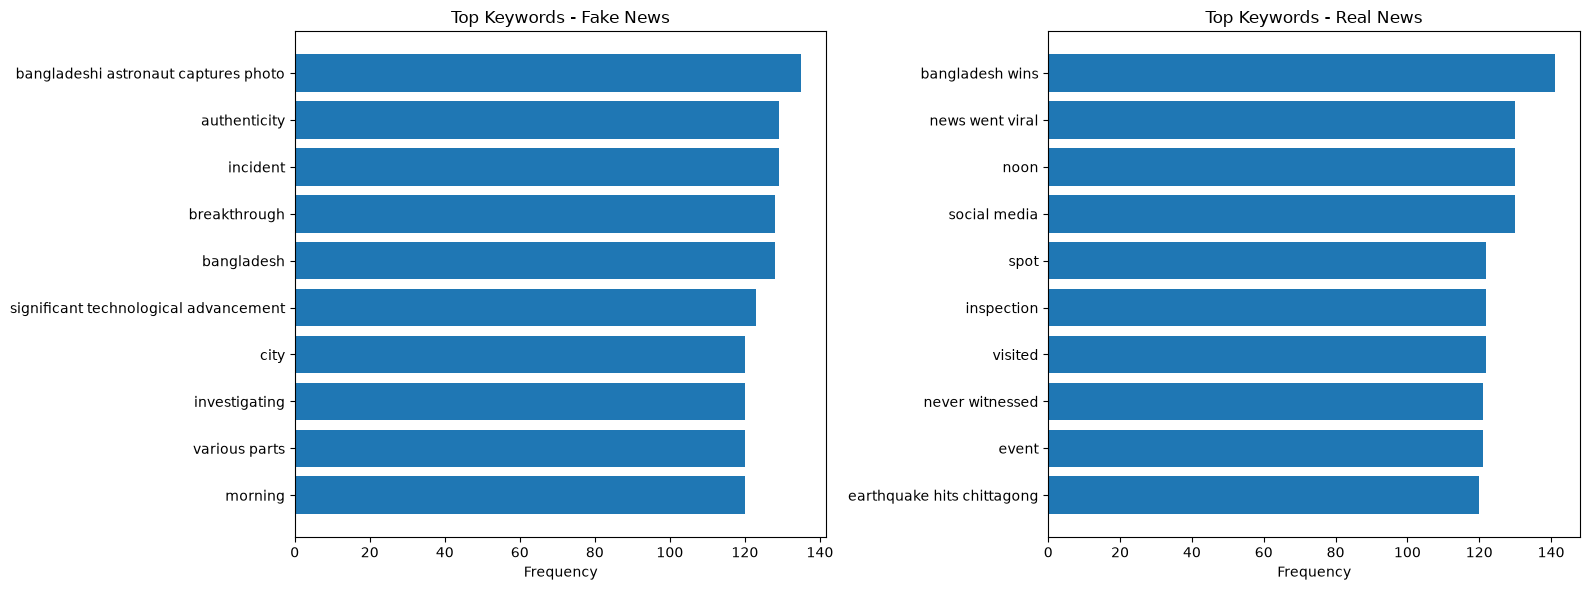

In [6]:
fake_top = fake_keywords.head(10)
real_top = real_keywords.head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(fake_top["keyword"], fake_top["frequency"])
axes[0].set_title("Top Keywords - Fake News")
axes[0].set_xlabel("Frequency")
axes[0].invert_yaxis()

axes[1].barh(real_top["keyword"], real_top["frequency"])
axes[1].set_title("Top Keywords - Real News")
axes[1].set_xlabel("Frequency")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

In [7]:
keyword_df.to_csv("T29_rake_keywords.csv", index=False)
keyword_comparison.to_csv("T29_keyword_comparison.csv", index=False)

print("Keyword extraction and comparison results saved successfully!")

Keyword extraction and comparison results saved successfully!
